In [24]:
from keras.models import Model
from keras.applications.mobilenet import MobileNet
import pathlib
from keras.preprocessing.image import ImageDataGenerator
from keras.callbacks import ModelCheckpoint,EarlyStopping
import tensorflow as tf
import matplotlib.pyplot as plt
%matplotlib inline
import os
import numpy as np
from keras import layers
from keras.layers import Dense



In [2]:
Batch_size = 16
Input_shape = (224,224,3)

model = MobileNet(input_shape=Input_shape)

In [5]:
data_dir =  pathlib.Path("dataset")
img_path  = len(list(data_dir.glob("*\*.jpg")))
print("total",img_path)

total 1376


In [6]:
class_names = np.array([names.name for names in data_dir.glob("*") ])

In [7]:
print(class_names)

['without_mask' 'with_mask']


In [17]:
Imagedatagenerator = ImageDataGenerator(shear_range=0.2,zoom_range=0.5,rescale=1/255.0,validation_split=0.2,
                                         width_shift_range=0.2,
                                     height_shift_range=0.2,
                                     horizontal_flip=True)



In [18]:
train_dataset = Imagedatagenerator.flow_from_directory(directory=str(data_dir),classes=list(class_names),batch_size=Batch_size,target_size=(224,224),)


testDataset = Imagedatagenerator.flow_from_directory(directory=str(data_dir), batch_size=Batch_size,
                                                    classes=list(class_names),
                                                    target_size=(224, 224),
                                                    shuffle=True, subset="validation")

Found 1376 images belonging to 2 classes.
Found 275 images belonging to 2 classes.


In [19]:
steps = np.ceil(train_dataset.samples/Batch_size)

In [ ]:
es = EarlyStopping(
    monitor='val_loss',patience=2,
    verbose=1,
)

mcp = ModelCheckpoint(
    filepath= "mobilenet.h5",save_best_only=True,verbose=1
)

In [21]:
model.layers.pop()

In [23]:
for layer in model.layers[:-4]:
    layer.trainable = False

In [26]:
output = Dense(units=2,activation='sigmoid')

output = output(model.layers[-1].output)

model = Model(inputs=model.input,outputs=output)

In [31]:
model.compile(loss="binary_crossentropy",metrics=['accuracy'],optimizer='adam')

In [32]:
model.summary()

Model: "model"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 input_1 (InputLayer)        [(None, 224, 224, 3)]     0         
                                                                 
 conv1 (Conv2D)              (None, 112, 112, 32)      864       
                                                                 
 conv1_bn (BatchNormalizatio  (None, 112, 112, 32)     128       
 n)                                                              
                                                                 
 conv1_relu (ReLU)           (None, 112, 112, 32)      0         
                                                                 
 conv_dw_1 (DepthwiseConv2D)  (None, 112, 112, 32)     288       
                                                                 
 conv_dw_1_bn (BatchNormaliz  (None, 112, 112, 32)     128       
 ation)                                                      

In [33]:
history = model.fit(train_dataset,epochs=10,steps_per_epoch=steps,validation_data=testDataset)

Epoch 1/10
86/86 [==============================] - 59s 676ms/step - loss: 0.6546 - accuracy: 0.9251 - val_loss: 0.6223 - val_accuracy: 0.9818
Epoch 2/10
86/86 [==============================] - 30s 349ms/step - loss: 0.5951 - accuracy: 0.9884 - val_loss: 0.5693 - val_accuracy: 0.9927
Epoch 3/10
86/86 [==============================] - 31s 361ms/step - loss: 0.5508 - accuracy: 0.9884 - val_loss: 0.5314 - val_accuracy: 0.9927
Epoch 4/10
86/86 [==============================] - 33s 384ms/step - loss: 0.5131 - accuracy: 0.9920 - val_loss: 0.4958 - val_accuracy: 0.9964
Epoch 5/10
86/86 [==============================] - 37s 433ms/step - loss: 0.4794 - accuracy: 0.9956 - val_loss: 0.4636 - val_accuracy: 0.9964
Epoch 6/10
86/86 [==============================] - 38s 440ms/step - loss: 0.4516 - accuracy: 0.9949 - val_loss: 0.4377 - val_accuracy: 0.9927
Epoch 7/10
86/86 [==============================] - 49s 572ms/step - loss: 0.4224 - accuracy: 0.9971 - val_loss: 0.4166 - val_accuracy: 0.9818

In [34]:
model.save("mobilenet.h5")

18/18 [==============================] - 5s 256ms/step - loss: 0.3454 - accuracy: 0.9927
Val loss: 0.3454342484474182
Val Accuracy: 99.2727279663086


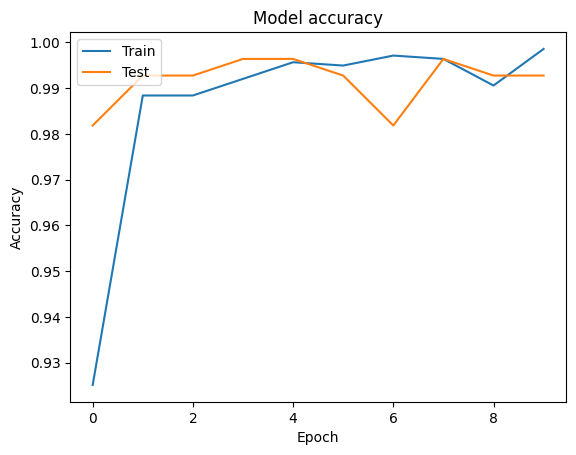

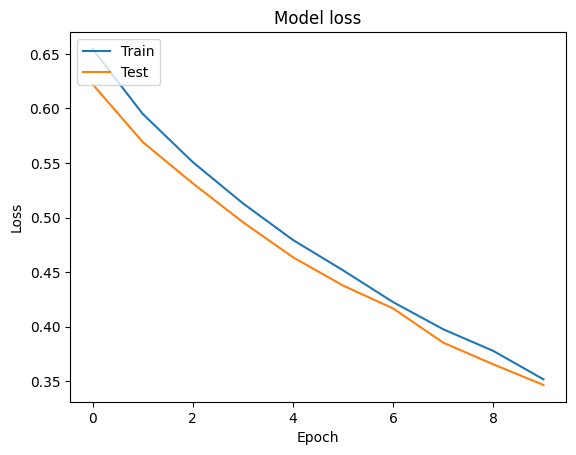

In [36]:
evaluation = model.evaluate(testDataset)
print("Val loss:", evaluation[0])
print("Val Accuracy:", evaluation[1]*100)

acc = history.history['accuracy']
val_acc = history.history['val_accuracy']
loss = history.history['loss']
val_loss = history.history['val_loss']
plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])
plt.title('Model accuracy')
plt.ylabel('Accuracy')
plt.xlabel('Epoch')
plt.legend(['Train', 'Test'], loc='upper left')
plt.show()

plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.title('Model loss')
plt.ylabel('Loss')
plt.xlabel('Epoch')
plt.legend(['Train', 'Test'], loc='upper left')
plt.show()